<a href="https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-0/07-graficos/clase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Episodio 0.7 · Gráficos

**Serie:** Del Excel al Machine Learning · **Temporada 0** · 🎬 Video próximamente

## 🎯 Qué vas a aprender

- Crear gráficos de **columnas**, **barras**, **líneas** y **circulares** con `.plot()`.
- Ponerles título y nombres a los ejes.
- Elegir el gráfico correcto para cada pregunta.
- Guardar un gráfico como imagen.

## 📊 En Excel lo harías así

1. Armas una **tabla dinámica** con el resumen.
2. **Insertar → Gráfico** y eliges el tipo.
3. Le pones título y nombres a los ejes.
4. El próximo mes, actualizas los datos y arreglas lo que se movió.

En Python es igual: primero el resumen y después el gráfico. La diferencia es que queda escrito.

## 🐍 En Python

### Paso 1: preparar los datos

**matplotlib** es la herramienta de Python que dibuja los gráficos. Colab ya la trae. Le decimos `plt`, como le decimos `pd` a pandas.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

DATOS = "https://raw.githubusercontent.com/PercyTechX/del-excel-al-ml/main/datos/"

In [2]:
ventas = pd.read_csv(DATOS + "ventas.csv")

ventas["fecha"] = pd.to_datetime(ventas["fecha"], format="%Y-%m-%d")
ventas["anio"] = ventas["fecha"].dt.year
ventas["mes"] = ventas["fecha"].dt.month

ventas.shape

(50000, 13)

### Paso 2: tu primer gráfico

Primero, el resumen, como en el episodio 0.6. Lo dividimos entre 1,000 para que el gráfico muestre miles de soles, sin tantos ceros.

Después, `.plot()` lo dibuja. `kind="bar"` hace lo que Excel llama **columnas**; las barras horizontales son `kind="barh"`. `plt.show()` cierra el gráfico: sin esa línea, verás además un texto técnico como `<Axes: ...>`, y si dibujas otro en la misma celda, saldrá encima. Haz cada gráfico en su celda.

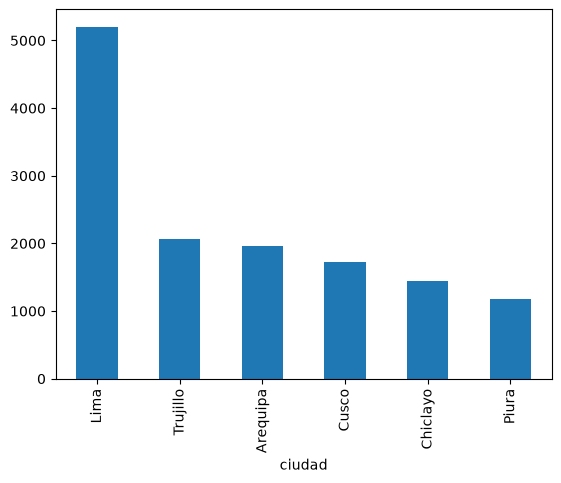

In [3]:
por_ciudad = ventas.groupby("ciudad")["total"].sum().sort_values(ascending=False) / 1000

por_ciudad.plot(kind="bar")
plt.show()

Funciona, pero nadie sabría qué está mirando. Agregamos las mismas opciones que en Excel: `title` para el título, `xlabel` y `ylabel` para los ejes, y `rot=0` para enderezar los nombres.

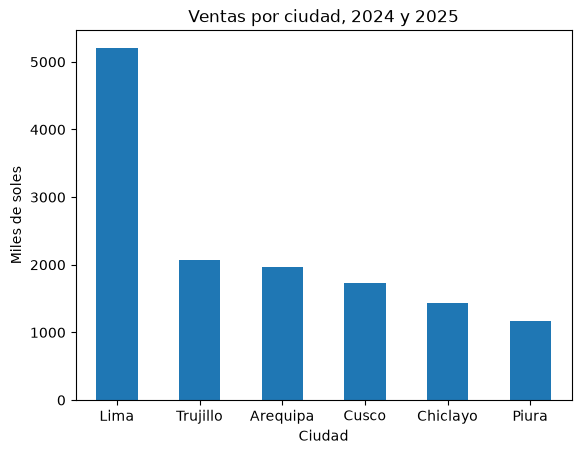

In [4]:
por_ciudad.plot(
    kind="bar",
    title="Ventas por ciudad, 2024 y 2025",
    xlabel="Ciudad",
    ylabel="Miles de soles",
    rot=0,
)
plt.show()

Un gráfico sin unidades obliga a adivinar. Por eso el eje dice **miles de soles**.

### Paso 3: líneas, para ver el tiempo

¿Cómo van las ventas durante el año? Con `pivot_table`, cada mes es una fila y cada año, una columna. `.plot()` dibuja **una línea por columna** y agrega la leyenda:

- `marker="o"` marca un punto en cada mes.
- `xticks` indica qué valores mostrar en el eje: `range(1, 13)` son los meses del 1 al 12.
- `ylim=(0, None)` hace que el eje empiece en 0. Sin esta opción, matplotlib empieza cerca del valor más bajo y las diferencias parecen más grandes.
- `plt.legend(title="Año")` cambia el título de la leyenda, que sería `anio`.

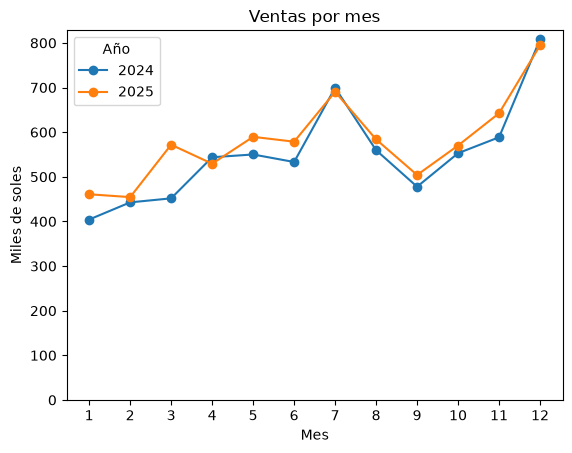

In [5]:
por_mes = ventas.pivot_table(index="mes", columns="anio", values="total", aggfunc="sum") / 1000

por_mes.plot(
    kind="line",
    marker="o",
    title="Ventas por mes",
    xlabel="Mes",
    ylabel="Miles de soles",
    xticks=range(1, 13),
    ylim=(0, None),
)
plt.legend(title="Año")
plt.show()

En un segundo se ven los picos de **julio** (Fiestas Patrias) y **diciembre** (Navidad), y que enero y febrero son flojos. En una tabla de 24 números, cuesta mucho más verlo.

### Paso 4: circular, para las partes de un todo

`autopct="%1.0f%%"` escribe el porcentaje sin decimales en cada parte. Es una receta: cópiala tal cual. `ylabel=""` evita un título lateral que no aporta.

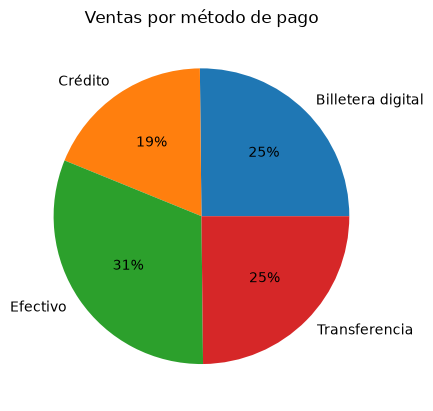

In [6]:
por_pago = ventas.groupby("metodo_pago")["total"].sum()

por_pago.plot(kind="pie", autopct="%1.0f%%", title="Ventas por método de pago", ylabel="")
plt.show()

### ¿Qué gráfico elijo?

| Tu pregunta | Gráfico | `kind` |
|---|---|---|
| ¿Quién vende más? | Columnas o barras | `"bar"` o `"barh"` |
| ¿Cómo cambia en el tiempo? | Líneas | `"line"` |
| ¿Qué parte del total es cada uno? | Circular, con pocas partes | `"pie"` |

> ⚠️ Con más de 5 o 6 partes, el circular ya no se lee: usa barras. Y en columnas y barras, mantén el eje desde 0, para no exagerar las diferencias.

### Paso 5: guardar la imagen

`plt.savefig()` guarda el gráfico en la carpeta 📁 de Colab, desde donde puedes descargarlo. Si no lo ves, actualiza la carpeta. Va **antes** de `plt.show()`: después, la imagen guardada saldría en blanco. Con `dpi=150` sale más nítida y `bbox_inches="tight"` evita que se corten los títulos.

> ⚠️ Esa carpeta es temporal: descarga la imagen antes de cerrar Colab.

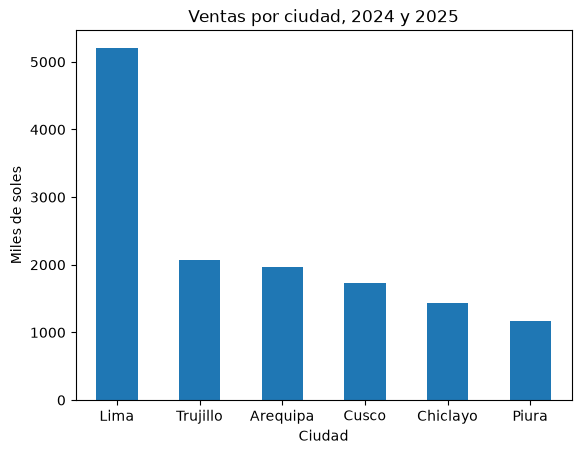

In [7]:
por_ciudad.plot(
    kind="bar",
    title="Ventas por ciudad, 2024 y 2025",
    xlabel="Ciudad",
    ylabel="Miles de soles",
    rot=0,
)
plt.savefig("ventas_por_ciudad.png", dpi=150, bbox_inches="tight")
plt.show()

## 🤖 Pídeselo a la IA

Los gráficos tienen muchas opciones, y nadie las recuerda todas. Es un gran uso de la IA:

> *"Tengo este gráfico de pandas: `por_ciudad.plot(kind="bar", title="Ventas por ciudad")`. ¿Cómo pongo cada barra de otro color y escribo el valor encima? Explícame cada línea."*

La IA te ayuda a escribir y entender código, pero **tú debes entender lo que hace**. Revisa cada respuesta antes de usarla, y mira si el gráfico dice lo que los datos dicen.

## ✅ Resumen

| En Excel | En Python |
|---|---|
| Insertar → Gráfico | `por_ciudad.plot(kind="bar")` |
| Columnas, barras, líneas, circular | `kind="bar"`, `"barh"`, `"line"`, `"pie"` |
| Título del gráfico | `title="..."` |
| Títulos de los ejes | `xlabel="..."`, `ylabel="..."` |
| Mostrar porcentajes | `autopct="%1.0f%%"` |
| Una serie por columna | `pivot_table` y luego `.plot()` |
| Guardar como imagen | `plt.savefig("grafico.png")` |

## 📝 Ahora te toca

Abre [el ejercicio en Colab](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-0/07-graficos/ejercicio.ipynb) y arma los gráficos de la gerencia. Cuando termines, compara con [la solución](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-0/07-graficos/solucion.ipynb).

---

*Del Excel al Machine Learning* · por [Percy Nazario](https://www.linkedin.com/in/percy-nazario/) · [Repositorio](https://github.com/PercyTechX/del-excel-al-ml) · Contenido bajo licencia CC BY 4.0